# 交接模式

是什么> 中间数据产物在节点间传递，前一个节点的产物是后面节点的输入。中间成果物是有关联的，像串行链但串行链的中间节点的各产物无关联，各自是各自的，

这个模式的关键是交接管理节点

In [1]:
import os
from typing import Annotated, List, Literal
from typing_extensions import TypedDict
import operator
from langchain_ollama import ChatOllama
from langgraph.graph import StateGraph, END, START
from langgraph.graph.message import add_messages
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage
from langchain.chat_models import init_chat_model

In [2]:
model_name = "qwen2.5:7b-instruct-q4_K_M"
model = ChatOllama(model=model_name)

## 状态

In [6]:
class TaskState(TypedDict):
    # 公共消息状态(对话模式:上下文)
    # messages:Annotated[List[BaseMessagel,add messages]
    # 小组的工作主题
    topic: str #生成模式(没有上下文)
    # 资料员的工作成果状态
    research_mertial: str  # 撰写著的士作成果状态
    # 撰写者的成果
    report: str
    #，下一个工作按照状态:agent
    next_agent: str #  agent的name。(工作交接):

## 数据处理 (Agent + Model[结构化输出])

In [7]:
#-------2 . 智能体节点 - 2.1. 资料员-----------
def research_agent(state: TaskState) -> dict:   # "researcher
    """
    资料员智能体：负责材料与信息收集
    """
    print("资料员正在收集材料...")
    # 资料收集的模型
    # 获取topic状态
    topic = state["topic"]
    # 收集资料
    response = model.invoke(F"争对主题:`{topic}`收集材料与信息，用3-5个要点总结") # 使用生成模式

    print(F"【资料员】收集的材料：\n{response.content[:100]}")
    return {
        "research_mertial":  response.content, 
        "next_agent": "writer"   # 这个状态的改变可以优化（由管理者来修改）
    }

## 中间结果 (Agent + Model[结构化输出])

In [15]:
# writer
def write_agent(state: TaskState) -> dict:
    """
    写作员智能体：负责报告与文章的撰写。
    """
    print("写作员正在写报告...")
    # 取出两个状态
    topic = state["topic"]
    research_mertial = state["research_mertial"]
    # 生成提示词
    prompt = F"""基于以下研究材料，撰写一篇关于`{topic}`的简短文章（100字左右）：
    研究材料：
    {research_mertial}
    
    文章要求：简洁、清晰、有吸引力、具有较强的逻辑性。
    """
    response = model.invoke(prompt)  # 生成模式
    print(F"【写作员】文章完成：\n{response.content}")
    return {
        "report": response.content,
        "next_agent": "finish"
    }

## 交接管理 ()

In [16]:
# supervisor
def supervise_agent(state: TaskState) -> dict:
    """
    管理者智能体：负责下一个智能体的任务安排
    """
    
    print("管理者正在协调工作...")
    if not state.get("research_mertial"):
        # 安排资料收集工作
        next_agent = "researcher"
        print("管理者安装资料员收集资料")
    elif not state.get("report"):
        next_agent = "writer"
        print("管理者安装写作员写文章")
    else:
        next_agent = "finish"
        print("所有工作完成")
    return {
        "next_agent": next_agent
    }

路由

In [17]:
# -----------3. 条件（智能判断流程） ----------
def condtional_goto(state: TaskState) -> Literal["researcher", "writer", END]:
    """
    路由器：决定下一个执行任务的智能体。
    """
    next_agent = state.get("next_agent", "")
    if next_agent == "researcher":
        return "researcher"
    elif next_agent == "writer":
        return "writer"
    elif next_agent == "finish":
        return END
    else:
        return END

图构建 这个模式的图核心是将路由转移的职责分出来一个管控节点(交接节点),图中所有状态的切管都要经过这个supervise

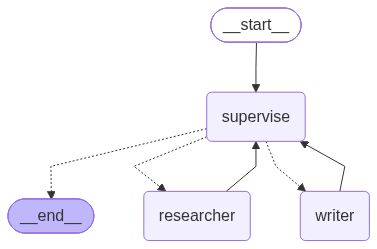

In [18]:
graph = StateGraph(Taskstate)

graph.add_node("researcher", research_agent)
graph.add_node("writer", write_agent)
graph.add_node("supervise", supervise_agent)

graph.set_entry_point("supervise")
graph.add_conditional_edges("supervise", condtional_goto, {
    "researcher": "researcher",
    "writer": "writer",
    END: END
})
graph.add_edge("researcher", "supervise")
graph.add_edge("writer", "supervise")
app = graph.compile()
app

In [19]:
topic = "人工智能对教育的影响"

# 初始状态
initial_state = {
    # "messages": [HumanMessage(content=f"研究主题：{topic}")],
    "topic": topic,
    "research_material": "",
    "final_article": "",
    "next_agent": ""
}
final_state = app.invoke(initial_state)
print(final_state)

管理者正在协调工作...
管理者安装资料员收集资料
资料员正在收集材料...
【资料员】收集的材料：
针对主题“人工智能对教育的影响”，以下是三个重要的要点总结：

1. **个性化学习的实现**：人工智能技术能够根据学生的学习习惯、能力水平和兴趣偏好，提供个性化的学习路径和资源推荐。这种个性化的学习
管理者正在协调工作...
管理者安装写作员写文章
写作员正在写报告...
【写作员】文章完成：
人工智能正深刻改变着教育的面貌。它通过个性化学习路径，使每位学生都能在最适合自己的节奏下进步。借助智能推荐和自动化工具，优质教育资源得以优化和普及，惠及更多地区的学生。此外，虚拟现实和增强现实技术的引入，为教学带来了创新的沉浸式体验，减轻了教师负担，使教育更加高效、公平。然而，技术的发展也需关注其可能带来的挑战。
管理者正在协调工作...
所有工作完成
{'topic': '人工智能对教育的影响', 'research_mertial': '针对主题“人工智能对教育的影响”，以下是三个重要的要点总结：\n\n1. **个性化学习的实现**：人工智能技术能够根据学生的学习习惯、能力水平和兴趣偏好，提供个性化的学习路径和资源推荐。这种个性化的学习方式有助于提高学习效率和效果，使得每位学生都能在最适合自己的节奏下学习。\n\n2. **教育资源的优化与普及**：借助人工智能，可以更有效地管理和优化教育资源，包括智能推荐高质量的教育资源、自动化批改作业、在线互动课程等。这不仅能够帮助偏远地区的学生获得优质的教育资源，还有助于实现教育资源的公平分配。\n\n3. **教学方法的创新与变革**：人工智能技术的应用促使了教育方式和模式的创新，如虚拟现实(VR)和增强现实(AR)技术的结合使用，能够提供沉浸式的学习体验；智能辅导系统的引入，可以减轻教师的教学负担，让他们有更多时间和精力专注于课程设计和学生个别指导。\n\n这些要点反映了人工智能在教育领域的广泛应用及其带来的积极影响，同时也提示了技术发展过程中可能面临的挑战和需要关注的问题。', 'report': '人工智能正深刻改变着教育的面貌。它通过个性化学习路径，使每位学生都能在最适合自己的节奏下进步。借助智能推荐和自动化工具，优质教育资源得以优化和普及，惠及更多地区的学生。此外，虚拟现实和增强现实技术的引入，为教学带来了创新的沉浸